# 🧠 Desenha Aí, Sô! — Parte 3: Fine-tuning do Zé do Rabisco (QLoRA + Unsloth) e Quantização GGUF

**UniRV · Engenharia de Software · Disciplinas:** Redes Neurais · Small Language Models — **Prof.:** Sandro S. Moreira
**Discente:** Gilberto Aparecido Dias Junior

---

| Etapa | O que acontece | Conteúdo da disciplina |
|---|---|---|
| 1 | Qwen3-1.7B carregado em **4 bits (NF4)** | quantização, arquitetura Qwen3 |
| 2 | Adaptadores **LoRA** em `q,k,v,o,gate,up,down` | QLoRA |
| 3 | **SFT** com *loss masking* (perda só na resposta) sobre o dataset destilado | destilação Teacher → Student |
| 4 | **Avaliação base × destilado** com as mesmas regras da curadoria + perplexidade | avaliação do Student |
| 5 | *Merge* + **GGUF Q4_K_M** para o `llama.cpp` (CPU, offline) | deploy na borda |
| 6 | Memória teórica (FP32/FP16/INT8/INT4) × arquivos reais | atividade de quantização |

O prompt, a avaliação, o critério de aprovação e a tabela de quantização vêm do pacote `desenha_ml`
(`prompt_qwen`, `avaliacao_do_ze`, `quantizacao`), testados e especificados no OpenSpec (`modelo-do-ze`). O prompt é o
**mesmo** que o jogo envia ao `llama-server` (contrato Python ↔ TypeScript).

> **Antes de rodar:** GPU **T4** (ou L4). A célula de instalação abre um menu de upload para o `desenha_ml-*.whl`, o
> `dataset_slm.zip` (Parte 2) e o `modelos_redes.zip` (Parte 1). O notebook já vem em **`MODO_ENSAIO = False`**
> (rodada completa, ≈ 40–60 min, gera o GGUF do Zé). O ensaio (`True`, ≈ 10 min) só testa as etapas e não vale para o
> critério de aprovação.

## 0. Instalação e configuração

In [1]:
import subprocess

import torch

if not torch.cuda.is_available():
    try:
        placa = subprocess.run(["nvidia-smi"], capture_output=True, text=True, check=False)
        diagnostico = (placa.stdout or placa.stderr or "sem saída").strip()[:600]
    except FileNotFoundError:  # sem GPU o Colab nem instala o nvidia-smi
        diagnostico = "nvidia-smi: não encontrado (o Colab não alocou GPU)"
    print(diagnostico)
    raise RuntimeError(
        "Sem GPU neste ambiente (veja o nvidia-smi acima: 'não encontrado' = o Colab não alocou GPU). "
        "Causas comuns: (1) você aceitou 'usar sem acelerador' no aviso de falta de GPU; (2) a cota de GPU do dia "
        "acabou (volta em até 24 h); (3) alta demanda: tente em alguns minutos. Para tentar de novo: Ambiente de "
        "execução → Desconectar e excluir ambiente de execução → Alterar o tipo → T4 (ou L4) → Salvar → Conectar, "
        "e confira o T4/L4 no canto superior direito antes de rodar."
    )
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


In [2]:
%%capture
%pip install unsloth

In [3]:
import base64
import glob
import os
from pathlib import Path

from google.colab import files
from IPython.display import HTML, display

PASTA_DOS_ARQUIVOS = "/content"
LIMITE_DO_BOTAO_EM_BYTES = 40 * 1024 * 1024  # o arquivo vai dentro do botão; acima disso usa o download normal


def exigir_arquivos(*padroes):
    """Abre o menu de upload do Colab enquanto faltar algum arquivo (eles caem em /content)."""
    os.chdir(PASTA_DOS_ARQUIVOS)
    while faltando := [p for p in padroes if not glob.glob(os.path.join(PASTA_DOS_ARQUIVOS, p))]:
        print("Faltam:", ", ".join(faltando), "→ escolha o(s) arquivo(s) na janela de upload que abriu.")
        if not files.upload():
            raise FileNotFoundError("Nenhum arquivo enviado; ainda faltam: " + ", ".join(faltando))


MODELO_DO_BOTAO = """
<button id="salvar" style="padding:8px 14px;font-size:14px;cursor:pointer">💾 Salvar __NOME__ (__TAMANHO__ MB) em…</button>
<span id="aviso" style="margin-left:10px"></span>
<script>
const nome = "__NOME__";
const blob = new Blob([Uint8Array.from(atob("__DADOS__"), c => c.charCodeAt(0))]);
const aviso = (texto) => { document.getElementById("aviso").textContent = texto; };
document.getElementById("salvar").onclick = async () => {
  try {
    const destino = await window.showSaveFilePicker({suggestedName: nome});
    const escrita = await destino.createWritable();
    await escrita.write(blob);
    await escrita.close();
    aviso("Salvo.");
  } catch (erro) {
    if (erro.name === "AbortError") { aviso("Cancelado."); return; }
    const a = document.createElement("a");
    a.href = URL.createObjectURL(blob);
    a.download = nome;
    a.click();
    aviso("Seu navegador não abriu a janela de escolha; baixei pelo método normal.");
  }
};
</script>
"""


def baixar_com_menu(caminho):
    """Mostra um botão que abre a janela "Salvar como" para você escolher onde guardar o arquivo.

    Funciona no Chrome e no Edge; em outro navegador (ou se ele bloquear a janela dentro do Colab) o botão
    baixa pelo método normal. Arquivos grandes demais para ir dentro do botão usam o download normal.
    """
    caminho = Path(caminho)
    tamanho = caminho.stat().st_size
    if tamanho > LIMITE_DO_BOTAO_EM_BYTES:
        print(f"{caminho.name} é grande ({tamanho / 1e6:.0f} MB): download normal.")
        files.download(str(caminho))
        return
    dados = base64.b64encode(caminho.read_bytes()).decode()
    botao = (MODELO_DO_BOTAO.replace("__NOME__", caminho.name)
             .replace("__TAMANHO__", f"{tamanho / 1e6:.1f}").replace("__DADOS__", dados))
    display(HTML(botao))

In [4]:
exigir_arquivos("desenha_ml-*.whl", "modelos_redes.zip", "dataset_slm.zip")
RODA = glob.glob("/content/desenha_ml-*.whl")
%pip install -q "{RODA[0]}"

Faltam: desenha_ml-*.whl, modelos_redes.zip, dataset_slm.zip → escolha o(s) arquivo(s) na janela de upload que abriu.


Saving dataset_slm.zip to dataset_slm.zip
Faltam: desenha_ml-*.whl, modelos_redes.zip → escolha o(s) arquivo(s) na janela de upload que abriu.


Saving modelos_redes.zip to modelos_redes.zip
Faltam: desenha_ml-*.whl → escolha o(s) arquivo(s) na janela de upload que abriu.


Saving desenha_ml-0.1.0-py3-none-any.whl to desenha_ml-0.1.0-py3-none-any.whl


In [5]:
from unsloth import FastLanguageModel  # antes de trl, transformers e peft, ou perde otimizações
from unsloth.chat_templates import train_on_responses_only

import dataclasses
import json, math, shutil, time, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from huggingface_hub import get_safetensors_metadata
from trl import SFTConfig, SFTTrainer

from desenha_ml.avaliacao_do_ze import avaliar_criterio_do_ze, avaliar_saida, resumir
from desenha_ml.ficha_tecnica import montar_ficha
from desenha_ml.prompt_qwen import INICIO_DA_RESPOSTA, PARADA, prompt_de_inferencia, texto_de_treino
from desenha_ml.quantizacao import tabela_de_quantizacao

MODO_ENSAIO = False                  # False = rodada completa (gera o GGUF); True = só testa as etapas (~10 min)
MODELO_BASE = "unsloth/Qwen3-1.7B"   # plano B mais rápido em CPU: "unsloth/Qwen3-0.6B" (D3 do design)
MODELO_ORIGINAL = "Qwen/Qwen3-1.7B"  # para contar os parâmetros reais (o 4-bit empacota 2 pesos por byte)
MAX_SEQ, TOKENS_NOVOS = 1024, 300
EXEMPLOS_DE_TESTE = 15 if MODO_ENSAIO else None
SAIDA = Path("/content/zedorabisco")
SAIDA.mkdir(exist_ok=True)
print(torch.cuda.get_device_name(0), "| VRAM", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB",
      "| MODO_ENSAIO =", MODO_ENSAIO)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1124 20:36:02.695000 319 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 20:36:02.752000 319 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
Tesla T4 | VRAM 15.6 GB | MODO_ENSAIO = False


## 1. Dataset destilado (Parte 2) e ficha técnica (Parte 1)

In [6]:
exigir_arquivos("dataset_slm.zip", "modelos_redes.zip")
with zipfile.ZipFile("/content/dataset_slm.zip") as arquivo_zip:
    arquivo_zip.extractall("/content/dataset_slm")
with zipfile.ZipFile("/content/modelos_redes.zip") as arquivo_zip:
    FICHA = montar_ficha(json.loads(arquivo_zip.read("metricas_redes.json")))
ler = lambda nome: pd.read_json(f"/content/dataset_slm/zedorabisco_{nome}_chatml.jsonl", lines=True)  # noqa: E731
treino, validacao, teste = ler("treino"), ler("val"), ler("teste")
if EXEMPLOS_DE_TESTE:
    teste = teste.groupby("tarefa").head(EXEMPLOS_DE_TESTE // 3)
print("treino", len(treino), "| validação", len(validacao), "| teste", len(teste), dict(teste.tarefa.value_counts()))

texto = lambda linha: texto_de_treino(linha.messages[1]["content"], linha.messages[2]["content"])  # noqa: E731
ds_treino = Dataset.from_list([{"text": texto(l)} for l in treino.itertuples()])
ds_validacao = Dataset.from_list([{"text": texto(l)} for l in validacao.itertuples()])
print(ds_treino[0]["text"])

treino 363 | validação 46 | teste 46 {'VEREDITO': np.int64(22), 'CHARADA': np.int64(16), 'PERGUNTA': np.int64(8)}
<|im_start|>system
Você é o Zé do Rabisco, locutor de rodeio goiano do jogo Desenha Aí, Sô!. Raciocine de forma curta dentro de <pensamento>...</pensamento> e responda dentro de <resposta>...</resposta>, em português, com humor caipira e respeitoso.<|im_end|>
<|im_start|>user
TAREFA: CHARADA
Palavra secreta: casa
Nível: fácil<|im_end|>
<|im_start|>assistant
<think>

</think>

<pensamento>Para o nivel facil com estilo de rodeio, pensei em paredes, teto e porta, que sao faceis de desenhar. Foco no telhado e na entrada que o peao conhece bem. Utiizei expressoes goianas moderadas e mantive a animacao sem citar a palavra casa.</pensamento>
<resposta>Charada: Segura peao, desenha logo paredes firmes, um telhado pontudo e uma porta aberta para receber o violeiro que chega cansado do gado, uai!</resposta><|im_end|>



## 2. Modelo base em 4 bits (NF4) + LoRA

In [7]:
model, tokenizer = FastLanguageModel.from_pretrained(MODELO_BASE, max_seq_length=MAX_SEQ, load_in_4bit=True)
print("VRAM após carregar em 4 bits:", round(torch.cuda.memory_allocated() / 1e9, 2), "GB")
N_PARAMETROS = sum(get_safetensors_metadata(MODELO_ORIGINAL).parameter_count.values())
print(f"Parâmetros do {MODELO_ORIGINAL} (metadados safetensors): {N_PARAMETROS:,}")

model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=16, lora_dropout=0, bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth", random_state=3407)
TREINAVEIS = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parâmetros treináveis (LoRA): {TREINAVEIS:,} = {100 * TREINAVEIS / N_PARAMETROS:.2f}% do modelo")

==((====))==  Unsloth 2026.11.11: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

VRAM após carregar em 4 bits: 1.41 GB


model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

Parâmetros do Qwen/Qwen3-1.7B (metadados safetensors): 2,031,739,904


Unsloth 2026.11.11 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
Parâmetros treináveis (LoRA): 17,432,576 = 0.86% do modelo


## 3. Geração em lote (infraestrutura) e avaliação do modelo **base**
A única função definida aqui é o laço de geração na GPU; as regras de avaliação vêm do pacote (`avaliar_saida`).

In [8]:
@torch.no_grad()
def gerar_respostas(prompts, lote=8):
    FastLanguageModel.for_inference(model)
    tokenizer.padding_side = "left"
    respostas, tokens = [], []
    parada = tokenizer.convert_tokens_to_ids(PARADA)
    for inicio in range(0, len(prompts), lote):
        entrada = tokenizer(prompts[inicio:inicio + lote], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        saida = model.generate(**entrada, max_new_tokens=TOKENS_NOVOS, do_sample=False, temperature=None, top_p=None,
                               top_k=None, eos_token_id=parada, pad_token_id=tokenizer.pad_token_id)
        for gerado in saida[:, entrada.input_ids.shape[1]:]:
            gerado = gerado[gerado != tokenizer.pad_token_id]
            tokens.append(len(gerado))
            respostas.append(tokenizer.decode(gerado, skip_special_tokens=True).strip())
    return respostas, tokens

exemplos_de_teste = [{"lote_id": "teste", "tarefa": l.tarefa, "entrada": l.messages[1]["content"], "meta": l.meta, "saida": None}
                     for l in teste.itertuples()]
prompts_de_teste = [prompt_de_inferencia(e["entrada"]) for e in exemplos_de_teste]
inicio = time.time()
with model.disable_adapter():
    respostas_base, tokens_base = gerar_respostas(prompts_de_teste)
avaliadas_base = [avaliar_saida(e, r, FICHA, t) for e, r, t in zip(exemplos_de_teste, respostas_base, tokens_base)]
resumo_base = resumir(avaliadas_base)
print(f"Base avaliado em {time.time() - inicio:.0f}s:", resumo_base)
print("Exemplo do base:\n", respostas_base[0][:500])

Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Base avaliado em 48s: ResumoDoModelo(formato=0.782608695652174, por_tarefa={'CHARADA': 0.0, 'VEREDITO': 0.0, 'PERGUNTA': 0.625}, tokens_medios=178.69565217391303)
Exemplo do base:
 <pensamento> Achar a palavra secreta "sol" no nível fácil é simples. É uma palavra que já está escrita, então a resposta é "sol". Mas com um toque de humor caipira, pode ser "sol" ou "só" (só é só, né?).

</pensamento>

<resposta> "Sol" é a palavra secreta. Mas se quiser um toque de humor, pode ser "só" (só é só, né? 😄). </resposta>


## 4. Treinamento (SFT com *loss masking*)
`train_on_responses_only` zera a perda dos tokens de *system* e *user*. A célula confere isso num exemplo antes de treinar.

In [9]:
FastLanguageModel.for_training(model)
tokenizer.padding_side = "right"
# o transformers novo trocou `warmup_ratio` por `warmup_steps` (valor < 1 = fração dos passos)
CHAVE_DO_AQUECIMENTO = "warmup_ratio" if "warmup_ratio" in {c.name for c in dataclasses.fields(SFTConfig)} else "warmup_steps"
AQUECIMENTO = {CHAVE_DO_AQUECIMENTO: 0.05}
trainer = SFTTrainer(
    model=model, tokenizer=tokenizer, train_dataset=ds_treino, eval_dataset=ds_validacao,
    args=SFTConfig(dataset_text_field="text", per_device_train_batch_size=4, gradient_accumulation_steps=4,
                   num_train_epochs=3, max_steps=10 if MODO_ENSAIO else -1, learning_rate=2e-4, **AQUECIMENTO,
                   lr_scheduler_type="cosine", optim="adamw_8bit", weight_decay=0.01, logging_steps=5,
                   eval_strategy="steps", eval_steps=5 if MODO_ENSAIO else 10, save_strategy="no", seed=3407,
                   output_dir=str(SAIDA / "treino"), report_to="none"))
trainer = train_on_responses_only(trainer, instruction_part="<|im_start|>user\n", response_part=INICIO_DA_RESPOSTA)

com_perda = tokenizer.decode([t for t in trainer.train_dataset[0]["labels"] if t != -100])
assert "<pensamento>" in com_perda and "TAREFA:" not in com_perda, "loss masking incorreto: a perda inclui a entrada"
print("Conferência do loss masking OK — trecho com perda:", com_perda[:160])

inicio = time.time()
estatisticas = trainer.train()
print(f"Treino: {(time.time() - inicio) / 60:.1f} min · pico de VRAM {torch.cuda.max_memory_reserved() / 1e9:.2f} GB")

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/363 [00:00<?, ? examples/s]

Unsloth: Packing train dataset (num_proc=2):   0%|          | 0/363 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/46 [00:00<?, ? examples/s]

Unsloth: Packing is on by default - documents are packed into full rows with no cross-document attention. Set packing = False in SFTConfig (or UNSLOTH_DEFAULT_PACKING=0) to turn it off.


Map:   0%|          | 0/110 [00:00<?, ? examples/s]

Map:   0%|          | 0/46 [00:00<?, ? examples/s]

... (2 outputs left out)

Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
10,2.526254,2.488653
20,2.220485,2.316891
21,2.220485,2.316310


Filter:   0%|          | 0/46 [00:00<?, ? examples/s]

Treino: 3.9 min · pico de VRAM 5.59 GB


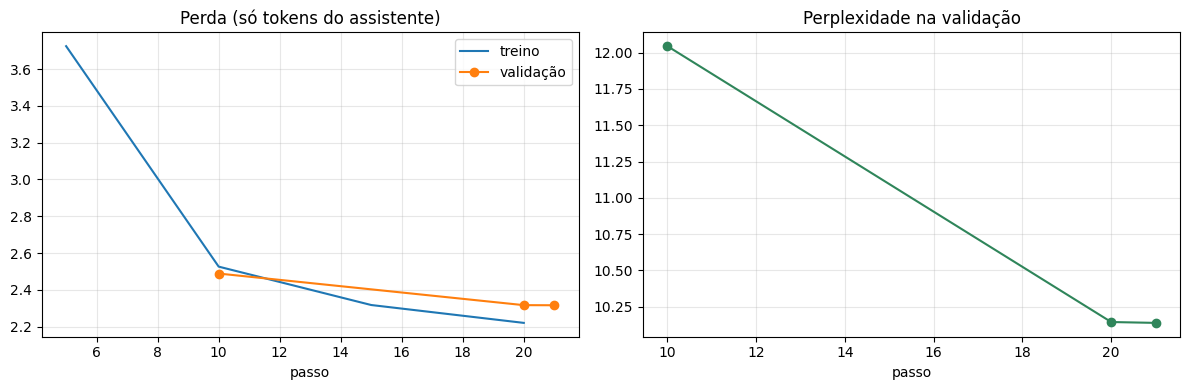

Training Loss,Validation Loss,Step
2.220485,4.482350,21


Training Loss,Validation Loss,Step
2.220485,2.316310,21


Perplexidade na validação — base: 88.44 · destilado: 10.14


In [10]:
historico = pd.DataFrame(trainer.state.log_history)
perda_treino, perda_val = historico.dropna(subset=["loss"]), historico.dropna(subset=["eval_loss"])
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(perda_treino.step, perda_treino.loss, label="treino")
eixos[0].plot(perda_val.step, perda_val.eval_loss, "o-", label="validação"); eixos[0].legend()
eixos[0].set_title("Perda (só tokens do assistente)")
eixos[1].plot(perda_val.step, np.exp(perda_val.eval_loss), "o-", c="#2f855a"); eixos[1].set_title("Perplexidade na validação")
for eixo in eixos: eixo.set_xlabel("passo"); eixo.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(SAIDA / "curvas_sft.png", dpi=150); plt.show()

with model.disable_adapter():
    perplexidade_base = math.exp(trainer.evaluate()["eval_loss"])
perplexidade_destilado = math.exp(trainer.evaluate()["eval_loss"])
print(f"Perplexidade na validação — base: {perplexidade_base:.2f} · destilado: {perplexidade_destilado:.2f}")

## 5. Avaliação do **Zé destilado** e critério de aprovação

In [11]:
respostas_destilado, tokens_destilado = gerar_respostas(prompts_de_teste)
avaliadas_destilado = [avaliar_saida(e, r, FICHA, t) for e, r, t in zip(exemplos_de_teste, respostas_destilado, tokens_destilado)]
resumo_destilado = resumir(avaliadas_destilado)
criterio = avaliar_criterio_do_ze(resumo_destilado, resumo_base, ensaio=MODO_ENSAIO)
tabela = pd.DataFrame({"Qwen3 base": {"formato": resumo_base.formato, **resumo_base.por_tarefa, "tokens médios": resumo_base.tokens_medios},
                       "Zé destilado": {"formato": resumo_destilado.formato, **resumo_destilado.por_tarefa,
                                        "tokens médios": resumo_destilado.tokens_medios}})
display(tabela.style.format("{:.2f}"))
print("CRITÉRIO DE APROVAÇÃO:", "APROVADO" if criterio.aprovado else ("ENSAIO" if criterio.aprovado is None else "REPROVADO"),
      criterio.motivos)

Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=300) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

,Qwen3 base,Zé destilado
formato,0.78,0.33
CHARADA,0.00,0.00
VEREDITO,0.00,0.00
PERGUNTA,0.62,0.50
tokens médios,178.70,244.87


CRITÉRIO DE APROVAÇÃO: REPROVADO ['formato: 32,6% < 95%', 'CHARADA: 0,0% < 85%', 'VEREDITO: 0,0% < 90%', 'PERGUNTA: 50,0% < 85%', 'formato: destilado 32,6% não supera o base 78,3%']


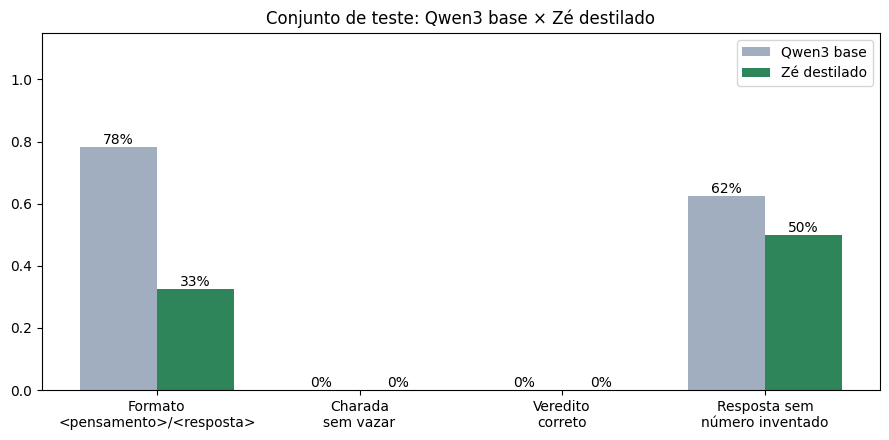

TAREFA: CHARADA
Palavra secreta: sol
Nível: fácil
--- BASE ---
<pensamento> Achar a palavra secreta "sol" no nível fácil é simples. É uma palavra que já está escrita, então a resposta é "sol". Mas com um toque de humor caipira, pode ser "sol" ou "só" (só é só, né?).

</pensamento>

<resposta> "Sol" é a palavra secreta. Mas se quiser um toque de humor, pode ser "só" (só é só, né? 😄). </resposta>
--- DESTILADO ---
<pensamento>O nível é fácil e a palavra secreta é sol. A resposta é simples e curta, com o tom de charada e humor caipira.</pensamento>
<resposta>CHARADA: SOL
NIVEL: FÁCIL
RESPOSTA: O sol nasce no amanhecer e se vai ao pôr do sol. O sol é o maior planeta do sistema solar e é o maior de todos. O sol é o maior planeta do sistema solar e é o maior de todos. O sol é o maior planeta do sistema solar e é o maior de todos. O sol é o maior planeta do sistema solar e é o maior de todos. O sol é o maior p
TAREFA: VEREDITO
Desafio: nuvem
Desenho concluído: 35%
CNN (imagem): nuvem 87%, pas

In [12]:
nomes = ["formato", "CHARADA", "VEREDITO", "PERGUNTA"]
x = np.arange(len(nomes)); largura = 0.38
fig, eixo = plt.subplots(figsize=(9, 4.5))
for i, (rotulo, resumo, cor) in enumerate([("Qwen3 base", resumo_base, "#a0aec0"), ("Zé destilado", resumo_destilado, "#2f855a")]):
    valores = [resumo.formato] + [resumo.por_tarefa.get(t, 0.0) for t in nomes[1:]]
    barras = eixo.bar(x + (i - 0.5) * largura, valores, largura, label=rotulo, color=cor)
    eixo.bar_label(barras, labels=[f"{100 * v:.0f}%" for v in valores])
eixo.set_xticks(x, ["Formato\n<pensamento>/<resposta>", "Charada\nsem vazar", "Veredito\ncorreto", "Resposta sem\nnúmero inventado"])
eixo.set_ylim(0, 1.15); eixo.legend(); eixo.set_title("Conjunto de teste: Qwen3 base × Zé destilado")
plt.tight_layout(); plt.savefig(SAIDA / "base_vs_destilado.png", dpi=150); plt.show()

for tarefa in ("CHARADA", "VEREDITO", "PERGUNTA"):
    i = next(j for j, e in enumerate(exemplos_de_teste) if e["tarefa"] == tarefa)
    print("=" * 100, f"\n{exemplos_de_teste[i]['entrada']}\n--- BASE ---\n{respostas_base[i][:500]}\n--- DESTILADO ---\n{respostas_destilado[i][:500]}")

## 6. Exportação GGUF e tabela de quantização (teoria da atividade 1 × arquivos reais)

In [13]:
inicio = time.time()
model.save_pretrained_gguf(str(SAIDA / "gguf"), tokenizer, quantization_method=["q4_k_m", "q8_0"])
print(f"GGUF exportado em {(time.time() - inicio) / 60:.1f} min")
arquivos_gguf = sorted(glob.glob(str(SAIDA / "**" / "*.gguf"), recursive=True) + glob.glob("/content/*.gguf"))
tamanhos = {("INT4" if "Q4_K_M" in Path(g).name.upper() else "INT8"): Path(g).stat().st_size / 1e9
            for g in arquivos_gguf if any(q in Path(g).name.upper() for q in ("Q4_K_M", "Q8_0"))}
quantizacao = tabela_de_quantizacao(N_PARAMETROS, tamanhos)
display(pd.DataFrame([vars(linha) for linha in quantizacao]).style.format(precision=3, na_rep="—"))

Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/752 [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in /content/zedorabisco/gguf/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/1 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

... (2 outputs left out)

Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [01:21<00:00, 81.31s/it]


Unsloth: Merge process complete. Saved to `/content/zedorabisco/gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m', 'q8_0'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b12675-mix-d14fe45 (app-b12675-mix-d14fe45-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['/content/zedorabisco/gguf_gguf/Qwen3-1.7B.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: [2] Converting GGUF f16 into q8_0. This might take 10

,formato,bytes_por_parametro,teorico_gb,cabe,margem_gb,real_gb
0,FP32,4.000,8.127,False,-5.327,—
1,FP16/BF16,2.000,4.063,False,-1.263,—
2,INT8,1.000,2.032,True,0.768,1.834
3,INT4,0.500,1.016,True,1.784,1.107


## 7. Artefatos no Drive

In [14]:
from google.colab import drive, files

drive.mount("/content/drive")
PASTA = Path("/content/drive/MyDrive/desenha_ai_so")
PASTA.mkdir(parents=True, exist_ok=True)
q4 = next(g for g in arquivos_gguf if "Q4_K_M" in Path(g).name.upper())
if not MODO_ENSAIO:
    shutil.copy(q4, PASTA / "zedorabisco-1.7b-Q4_K_M.gguf")
metricas = {
    "ensaio": MODO_ENSAIO, "modelo_base": MODELO_BASE, "parametros": N_PARAMETROS,
    "lora": {"r": 16, "alpha": 16, "treinaveis": TREINAVEIS, "percentual": 100 * TREINAVEIS / N_PARAMETROS},
    "dados": {"treino": len(treino), "validacao": len(validacao), "teste": len(teste)},
    "perplexidade_validacao": {"base": perplexidade_base, "destilado": perplexidade_destilado},
    "teste": {"base": vars(resumo_base), "destilado": vars(resumo_destilado)},
    "criterio": {"aprovado": criterio.aprovado, "motivos": criterio.motivos},
    "quantizacao": [vars(linha) for linha in quantizacao],
}
(SAIDA / "metricas_slm.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=1), encoding="utf8")
pd.DataFrame({"tarefa": [e["tarefa"] for e in exemplos_de_teste], "entrada": [e["entrada"] for e in exemplos_de_teste],
              "base": respostas_base, "destilado": respostas_destilado,
              "base_ok": [a.tarefa_ok for a in avaliadas_base], "destilado_ok": [a.tarefa_ok for a in avaliadas_destilado]}
             ).to_csv(SAIDA / "saidas_teste_base_vs_destilado.csv", index=False)
for nome in ("metricas_slm.json", "saidas_teste_base_vs_destilado.csv", "curvas_sft.png", "base_vs_destilado.png"):
    shutil.copy(SAIDA / nome, PASTA / (("ensaio_" if MODO_ENSAIO else "") + nome))
print("Copiado para", PASTA, "→ baixe o .gguf pelo Drive (o download de > 1 GB pelo navegador costuma falhar).")
baixar_com_menu(SAIDA / "metricas_slm.json")

Mounted at /content/drive
Copiado para /content/drive/MyDrive/desenha_ai_so → baixe o .gguf pelo Drive (o download de > 1 GB pelo navegador costuma falhar).


## 8. Próximos passos (fora do Colab)
1. No Google Drive, pasta `desenha_ai_so/`, baixe `zedorabisco-1.7b-Q4_K_M.gguf` e `metricas_slm.json`
   (clique direito → Fazer download; o download direto de mais de 1 GB pelo notebook costuma falhar).
2. Coloque os dois em `notebooks/resultados/` do projeto.
3. Só siga para a demo se o critério acima disser **APROVADO**.

In [15]:
print("Rodada completa" if not MODO_ENSAIO else "ENSAIO (não gera o GGUF final)")
print("Critério de aprovação:", "APROVADO" if criterio.aprovado else ("ENSAIO" if criterio.aprovado is None else "REPROVADO"), criterio.motivos)
print("No Drive:", PASTA, "→ zedorabisco-1.7b-Q4_K_M.gguf e metricas_slm.json")
print("Coloque os dois em notebooks/resultados/ do projeto e me avise.")
if criterio.aprovado is False:
    print("ATENÇÃO: critério REPROVADO. Não use este GGUF na demo; mande esta saída para ajustar o treino.")

Rodada completa
Critério de aprovação: REPROVADO ['formato: 32,6% < 95%', 'CHARADA: 0,0% < 85%', 'VEREDITO: 0,0% < 90%', 'PERGUNTA: 50,0% < 85%', 'formato: destilado 32,6% não supera o base 78,3%']
No Drive: /content/drive/MyDrive/desenha_ai_so → zedorabisco-1.7b-Q4_K_M.gguf e metricas_slm.json
Coloque os dois em notebooks/resultados/ do projeto e me avise.
ATENÇÃO: critério REPROVADO. Não use este GGUF na demo; mande esta saída para ajustar o treino.
